# Time Series Foundations: Decomposition, Stationarity, Autocorrelation

**What you'll learn**

- How to decompose real series (Mauna Loa CO2, airline passengers, a simulated retail
  series with promotions) into trend / seasonal / remainder with STL, how to *choose*
  additive vs multiplicative form from the data, and what a healthy remainder looks like —
  plus using the remainder for event/anomaly detection.
- Stationarity as the license to learn from history: what ADF and KPSS actually test
  (they answer *different* questions), the 2x2 interpretation grid, and the
  trend-stationary vs difference-stationary distinction that decides *which* fix
  (detrend vs difference) is correct.
- ACF/PACF literacy built by experiment: simulate AR, MA, ARMA and seasonal processes
  with known orders and verify the identification table on the plots, not from memory.
- Spurious regression: two *independent* random walks correlate "significantly" most of
  the time. We quantify how often, connect it to everyday KPI-correlation analyses, and
  show the remedies (differencing; cointegration for genuine level relationships).
- Why autocorrelation silently breaks naive inference: the SE of the mean of an AR(1)
  series vs the iid formula, simulated undercoverage of textbook CIs, and the fixes
  (HAC / Newey–West, AR(1) plug-in, block bootstrap).

**Why it matters in interviews**

- "Is this series stationary, and why do you care?" is the single most common time-series
  screen. The expected answer covers *both* tests, their opposite null hypotheses, and
  what you'd do in each cell of the 2x2 grid.
- "These two KPIs correlate at 0.9 — what do you conclude?" is a planted spurious-regression
  trap. Senior candidates reach for differencing/cointegration before causal language.
- "Read this ACF/PACF plot" comes up in forecasting rounds; the identification table has
  to be automatic, including the seasonal-lag signature.
- Metric/experiment questions ("has the KPI shifted vs target?") hinge on knowing that
  `s/sqrt(n)` is wrong for autocorrelated data — quantifying *how* wrong is a senior move.

Prerequisites: sampling distributions and the bootstrap from
[../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy.signal import lfilter
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
from statsmodels.tsa.arima_process import arma_generate_sample
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)

# Data cache: notebook normally runs from 05_time_series/, but be robust to repo root.
DATA_DIR = Path("../data") if Path("../STYLE.md").exists() else Path("data")
DATA_DIR.mkdir(exist_ok=True)

## 1. Three series, three decomposition stories

We work with:

1. **CO2** (statsmodels, Mauna Loa weekly → monthly): smooth trend + stable annual
   seasonal cycle → the textbook **additive** series.
2. **Flights** (seaborn, the classic 1949–1960 airline passengers): growing trend *and*
   growing seasonal amplitude → the textbook **multiplicative** series.
3. **Simulated daily retail sales**: exponential growth x day-of-week pattern x annual
   cycle x random promotions x noise. Simulation gives us ground truth, so we can check
   that the decomposition's remainder recovers exactly what it should: the promotions.

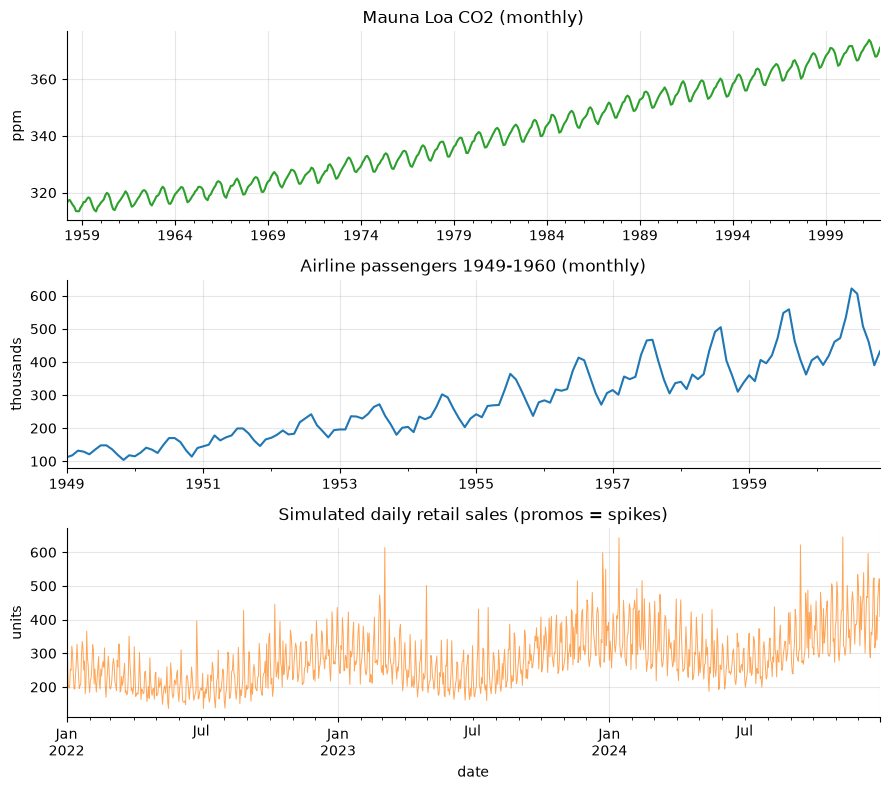

In [2]:
# --- CO2: bundled with statsmodels (no download) ---
co2_raw = sm.datasets.co2.load_pandas().data
co2 = co2_raw["co2"].resample("MS").mean().interpolate()  # weekly -> monthly, fill gaps

# --- Flights: seaborn loader with a local cache in data/ (offline-safe fallback) ---
_AIRPASS = [112,118,132,129,121,135,148,148,136,119,104,118,
            115,126,141,135,125,149,170,170,158,133,114,140,
            145,150,178,163,172,178,199,199,184,162,146,166,
            171,180,193,181,183,218,230,242,209,191,172,194,
            196,196,236,235,229,243,264,272,237,211,180,201,
            204,188,235,227,234,264,302,293,259,229,203,229,
            242,233,267,269,270,315,364,347,312,274,237,278,
            284,277,317,313,318,374,413,405,355,306,271,306,
            315,301,356,348,355,422,465,467,404,347,305,336,
            340,318,362,348,363,435,491,505,404,359,310,337,
            360,342,406,396,420,472,548,559,463,407,362,405,
            417,391,419,461,472,535,622,606,508,461,390,432]

def load_flights() -> pd.Series:
    fp = DATA_DIR / "flights.csv"
    if fp.exists():
        raw = pd.read_csv(fp)
    else:
        try:
            raw = sns.load_dataset("flights")
        except Exception:  # no network: reconstruct the classic AirPassengers table
            raw = pd.DataFrame({"year": np.repeat(np.arange(1949, 1961), 12),
                                "month": np.tile(np.arange(1, 13), 12),
                                "passengers": _AIRPASS})
        raw.to_csv(fp, index=False)
    month = raw["month"]
    if not np.issubdtype(np.asarray(month).dtype, np.number):
        month = pd.to_datetime(month.astype(str), format="%b").dt.month
    idx = pd.to_datetime(pd.DataFrame({"year": raw["year"], "month": month, "day": 1}))
    s = pd.Series(raw["passengers"].to_numpy(float), index=idx, name="passengers")
    return s.sort_index().asfreq("MS")

flights = load_flights()

# --- Simulated daily retail sales with promotions (ground truth known) ---
n_days = 3 * 365
dates = pd.date_range("2022-01-01", periods=n_days, freq="D")
t = np.arange(n_days)
trend_true = 200 * np.exp(0.00045 * t)                      # ~64% growth over 3 years
dow_factor = np.array([0.95, 0.90, 0.92, 0.98, 1.10, 1.35, 1.28])[dates.dayofweek]
annual = 1 + 0.18 * np.cos(2 * np.pi * (t - 355) / 365.25)  # peak near late December
promo = rng.random(n_days) < 0.06                           # ~6% of days are promo days
lift = np.where(promo, rng.uniform(1.15, 1.60, n_days), 1.0)
noise = np.exp(rng.normal(0.0, 0.10, n_days))
retail = pd.Series(trend_true * dow_factor * annual * lift * noise,
                   index=dates, name="units_sold")

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=False)
co2.plot(ax=axes[0], color="tab:green")
axes[0].set(title="Mauna Loa CO2 (monthly)", ylabel="ppm", xlabel="")
flights.plot(ax=axes[1], color="tab:blue")
axes[1].set(title="Airline passengers 1949-1960 (monthly)", ylabel="thousands", xlabel="")
retail.plot(ax=axes[2], color="tab:orange", alpha=0.7, lw=0.7)
axes[2].set(title="Simulated daily retail sales (promos = spikes)", ylabel="units",
            xlabel="date")
plt.show()

### 1.1 Additive vs multiplicative — decide from the data, not by habit

- **Additive**: $y_t = T_t + S_t + R_t$ — seasonal swing has constant *absolute* size.
- **Multiplicative**: $y_t = T_t \cdot S_t \cdot R_t$ — seasonal swing is a constant
  *percentage* of the level. Most business volume metrics (sales, traffic, GMV) are
  multiplicative because processes scale with size.

Two quick diagnostics, demonstrated on `flights`:

1. **Amplitude vs level**: group by year; if the within-year std grows proportionally
   with the yearly mean (log–log slope near 1), the series is multiplicative and `log`
   stabilizes it (Box–Cox with lambda near 0).
2. **Fit both, inspect the residuals**: the wrong form leaves residuals whose spread
   scales with the trend.

log-log slope of (yearly std vs yearly mean): 1.31  (~1 => multiplicative -> take logs; ~0 => additive)
corr(|residual|, trend level) — additive fit:       +0.09
corr(|residual|, trend level) — multiplicative fit: -0.13


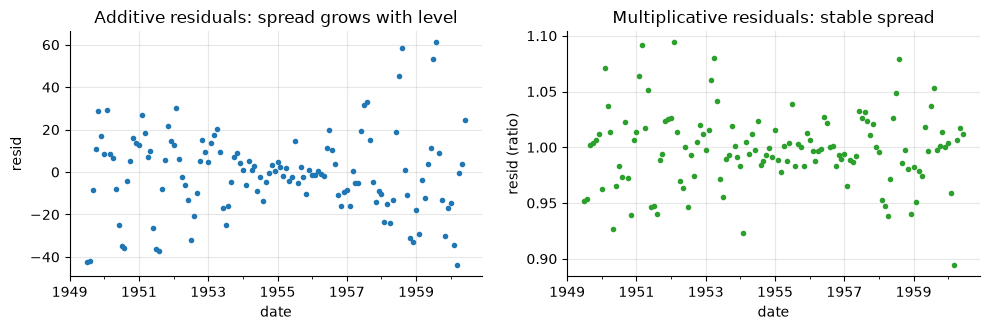

In [3]:
yearly = flights.groupby(flights.index.year).agg(["mean", "std"])
slope = np.polyfit(np.log(yearly["mean"]), np.log(yearly["std"]), 1)[0]
print(f"log-log slope of (yearly std vs yearly mean): {slope:.2f}  "
      "(~1 => multiplicative -> take logs; ~0 => additive)")

dec_add = seasonal_decompose(flights, model="additive", period=12)
dec_mul = seasonal_decompose(flights, model="multiplicative", period=12)

mask = dec_add.resid.notna()
corr_add = np.corrcoef(dec_add.trend[mask], np.abs(dec_add.resid[mask]))[0, 1]
corr_mul = np.corrcoef(dec_mul.trend[mask], np.abs(dec_mul.resid[mask] - 1))[0, 1]
print(f"corr(|residual|, trend level) — additive fit:       {corr_add:+.2f}")
print(f"corr(|residual|, trend level) — multiplicative fit: {corr_mul:+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
dec_add.resid.plot(ax=axes[0], marker=".", ls="none")
axes[0].set(title="Additive residuals: spread grows with level", ylabel="resid",
            xlabel="date")
dec_mul.resid.plot(ax=axes[1], marker=".", ls="none", color="tab:green")
axes[1].set(title="Multiplicative residuals: stable spread", ylabel="resid (ratio)",
            xlabel="date")
plt.show()

The additive fit's residuals fan out as the airline grows and their absolute size
correlates with the trend — the model form is wrong, not the data. In practice you
rarely fit a "multiplicative decomposition" directly: **take logs and work additively**.
That is also exactly what a SARIMA-on-log or an exponential-smoothing model with
multiplicative seasonality is doing under the hood.

### 1.2 STL: the workhorse decomposition

`seasonal_decompose` is a moving-average teaching tool: rigid, loses `period/2` points at
each end, and assumes a *fixed* seasonal pattern. **STL** (Seasonal-Trend decomposition
using Loess) is what you should reach for:

- the seasonal component may **evolve** over time (`seasonal=` window controls how fast),
- `robust=True` downweights outliers so events don't contaminate trend/seasonal,
- full-length components, no lost endpoints.

STL is additive — so feed it `log(y)` for multiplicative series.

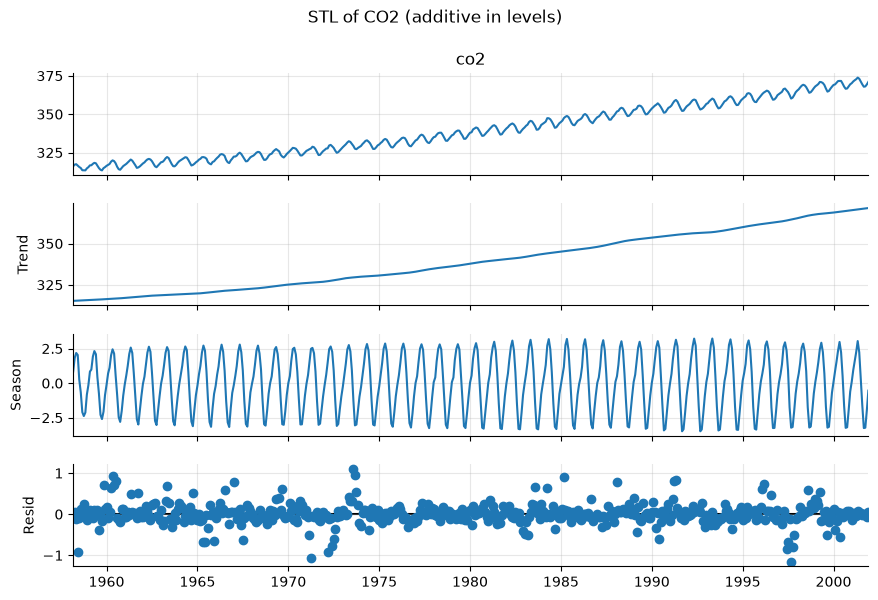

In [4]:
stl_co2 = STL(co2, period=12, robust=True).fit()
fig = stl_co2.plot()
fig.set_size_inches(9, 6)
fig.suptitle("STL of CO2 (additive in levels)", y=1.02)
plt.show()

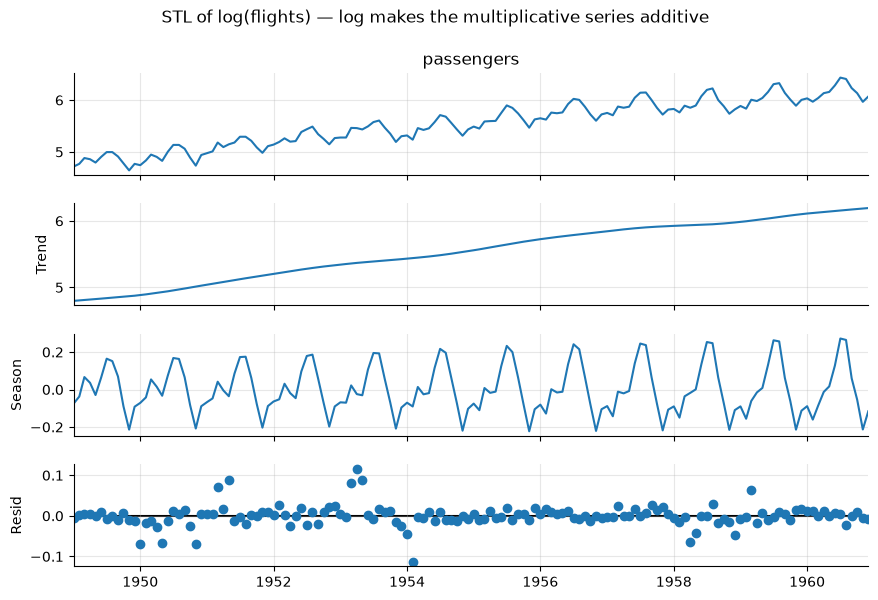

In [5]:
stl_fl = STL(np.log(flights), period=12, robust=True).fit()
fig = stl_fl.plot()
fig.set_size_inches(9, 6)
fig.suptitle("STL of log(flights) — log makes the multiplicative series additive", y=1.02)
plt.show()

### 1.3 Interpreting the remainder — and using it

The remainder is *everything your trend + seasonal model cannot explain*. Checklist for a
healthy decomposition:

- **No leftover seasonality** in the remainder (check its ACF at the seasonal lag —
  a spike at lag 7/12 means the seasonal window is wrong or seasonality changed).
- **No level-dependent spread** (fan shape means wrong additive/multiplicative choice,
  see 1.1).
- **Spikes are information, not noise**: holidays, promotions, outages, data bugs live
  in the remainder. Robust STL is deliberately built so such events stay in the
  remainder instead of bending the trend.

A useful summary is the **strength of seasonality / trend** (Hyndman):
$F_S = \max\!\big(0,\, 1 - \mathrm{Var}(R)/\mathrm{Var}(S + R)\big)$, and the analogue
with $T$ for trend. Values near 1 mean the component dominates.

In [6]:
def component_strength(res) -> dict:
    r = res.resid.to_numpy()
    s = res.seasonal.to_numpy()
    tr = res.trend.to_numpy()
    return {"trend strength": max(0, 1 - np.nanvar(r) / np.nanvar(tr + r)),
            "seasonal strength": max(0, 1 - np.nanvar(r) / np.nanvar(s + r))}

stl_retail = STL(np.log(retail), period=7, robust=True).fit()

strength = pd.DataFrame({"CO2": component_strength(stl_co2),
                         "log flights": component_strength(stl_fl),
                         "log retail (weekly)": component_strength(stl_retail)}).T
print(strength.round(3))

                     trend strength  seasonal strength
CO2                           1.000              0.984
log flights                   0.996              0.959
log retail (weekly)           0.761              0.672


Note on the retail series: it has **two** seasonalities (weekly and annual). STL handles
one period at a time — with `period=7` the annual cycle is absorbed into the "trend"
curve. That is fine for weekly-pattern analysis, but know that `MSTL` (statsmodels) or
Prophet-style regression handle multiple seasonalities explicitly.

Now the payoff of simulating: we *know* which days were promotions. Let's verify that the
remainder isolates them — remainder-based **event/anomaly detection** is a bread-and-butter
industry use of decomposition.

mean remainder on promo days:     +0.247  (log scale)
mean remainder on non-promo days: -0.003
flagging remainder > 3*sigma: precision = 68.8%, recall = 48.5%  (48 flags, 68 promos)


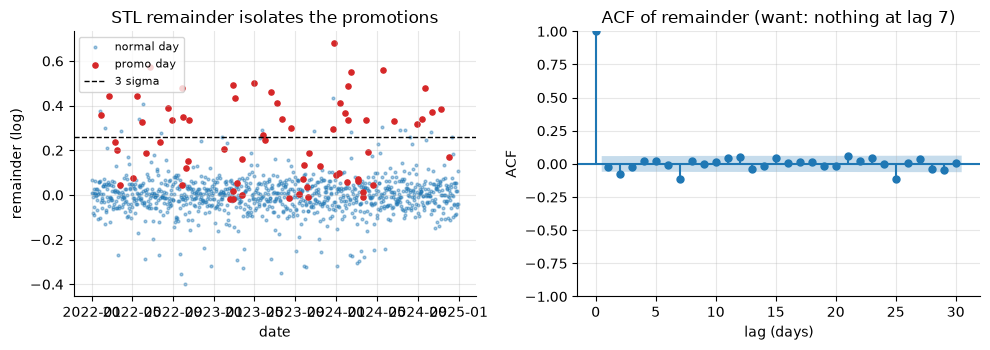

In [7]:
resid = stl_retail.resid.to_numpy()
sigma_bg = resid[~promo].std()  # background noise scale (non-promo days)
flagged = resid > 3 * sigma_bg

print(f"mean remainder on promo days:     {resid[promo].mean():+.3f}  (log scale)")
print(f"mean remainder on non-promo days: {resid[~promo].mean():+.3f}")
print(f"flagging remainder > 3*sigma: precision = {promo[flagged].mean():.1%}, "
      f"recall = {flagged[promo].mean():.1%}  ({flagged.sum()} flags, {promo.sum()} promos)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(dates[~promo], resid[~promo], s=4, alpha=0.4, label="normal day")
axes[0].scatter(dates[promo], resid[promo], s=14, color="tab:red", label="promo day")
axes[0].axhline(3 * sigma_bg, color="k", ls="--", lw=1, label="3 sigma")
axes[0].set(title="STL remainder isolates the promotions", xlabel="date",
            ylabel="remainder (log)")
axes[0].legend(loc="upper left", fontsize=8)
plot_acf(resid, lags=30, ax=axes[1], title="ACF of remainder (want: nothing at lag 7)")
axes[1].set(xlabel="lag (days)", ylabel="ACF")
plt.show()

The remainder's ACF shows no spike at lag 7 — the weekly pattern was fully captured — and
promo days stand out cleanly above the noise band. In a real pipeline this exact pattern
(STL-robust, threshold the remainder) is a strong, simple anomaly detector for KPIs.

## 2. Stationarity: the license to learn from history

A (weakly) stationary series has constant mean, constant variance, and autocovariances
that depend only on the lag. Why you should care, concretely:

- **Estimation**: the sample mean/variance/ACF are only consistent estimates of anything
  if the underlying quantities exist and are constant. The "ACF" of a trending series is
  a plot of the trend, not of dependence.
- **Modeling**: ARMA theory, standard regression inference, and most classical forecast
  machinery assume stationarity (possibly *after* transformations — that's what the "I"
  in ARIMA is).
- **Forecasting = extrapolating a distribution**: if the distribution drifts, history is
  only informative once you model the drift (trend/seasonality) or remove it.

### 2.1 ADF and KPSS answer different questions — always run both

| Test | Null hypothesis H0 | Rejecting means... |
|---|---|---|
| **ADF** (augmented Dickey–Fuller) | series has a **unit root** (non-stationary) | evidence *for* stationarity |
| **KPSS** | series is **(trend-)stationary** | evidence *against* stationarity |

Because the nulls point in opposite directions, the pair is far more informative than
either alone — failing to reject ADF may just be low power, and the two tests disagree in
exactly the situations that deserve your attention:

| | KPSS does **not** reject (looks stationary) | KPSS **rejects** (not stationary) |
|---|---|---|
| **ADF rejects** (no unit root) | **Stationary** — model in levels | **Conflict** — trend-stationarity (rerun with trend terms), structural break, heteroskedasticity: investigate |
| **ADF does not reject** | **Inconclusive** — short/persistent sample, low power | **Unit root** — difference it |

(KPSS p-values from statsmodels are clamped to [0.01, 0.10] — they come from a lookup
table.)

In [8]:
def stationarity_report(x, regression: str = "c") -> dict:
    """Run ADF + KPSS with the same deterministic terms and combine the verdicts.

    regression: 'c' = stationary around a constant, 'ct' = around a linear trend.
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    adf_p = adfuller(x, regression=regression, autolag="AIC")[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_p = kpss(x, regression=regression, nlags="auto")[1]
    if adf_p < 0.05 and kpss_p >= 0.05:
        verdict = "stationary" + (" (around trend)" if regression == "ct" else "")
    elif adf_p >= 0.05 and kpss_p < 0.05:
        verdict = "unit root -> difference"
    elif adf_p < 0.05 and kpss_p < 0.05:
        verdict = "CONFLICT -> check trend/breaks"
    else:
        verdict = "inconclusive (low power)"
    return {"regression": regression, "ADF p": round(adf_p, 4),
            "KPSS p": round(kpss_p, 4), "verdict": verdict}

n = 400
white = rng.standard_normal(n)
ar95 = lfilter([1.0], [1.0, -0.95], rng.standard_normal(n + 200))[200:]
random_walk = np.cumsum(rng.standard_normal(n))
trend_noise = 0.03 * np.arange(n) + rng.standard_normal(n)

report = pd.DataFrame({
    "white noise": stationarity_report(white, "c"),
    "AR(1) phi=0.95 (stationary, persistent)": stationarity_report(ar95, "c"),
    "random walk": stationarity_report(random_walk, "c"),
    "random walk  [ct]": stationarity_report(random_walk, "ct"),
    "trend + noise": stationarity_report(trend_noise, "c"),
    "trend + noise [ct]": stationarity_report(trend_noise, "ct"),
}).T
print(report)

                                        regression   ADF p  KPSS p  \
white noise                                      c     0.0  0.0794   
AR(1) phi=0.95 (stationary, persistent)          c    0.17    0.01   
random walk                                      c  0.3334    0.01   
random walk  [ct]                               ct    0.55    0.01   
trend + noise                                    c  0.9219    0.01   
trend + noise [ct]                              ct     0.0     0.1   

                                                           verdict  
white noise                                             stationary  
AR(1) phi=0.95 (stationary, persistent)    unit root -> difference  
random walk                                unit root -> difference  
random walk  [ct]                          unit root -> difference  
trend + noise                              unit root -> difference  
trend + noise [ct]                       stationary (around trend)  


Read the table against the grid:

- **White noise**: ADF rejects, KPSS doesn't — clean "stationary".
- **Random walk**: ADF can't reject, KPSS rejects — clean "difference it", under either
  specification.
- **Trend + noise with `regression='c'`**: the tests typically push you toward
  "non-stationary" — *misleading*, because neither test was asked the right question.
  With `'ct'` the same series comes back **stationary around a trend**. Lesson: if a
  plot shows a trend, run the trend variants before concluding "unit root".
- **Persistent AR(1)** (phi = 0.95): the honest hard case. Near-unit-root and unit-root
  processes are nearly indistinguishable at this sample size; depending on the draw this
  row lands in "inconclusive" or worse. Unit-root tests have low power here — say so in
  an interview rather than pretending the tests settle it.

### 2.2 Trend-stationary vs difference-stationary — the fix depends on the diagnosis

Both of these grow at 0.05/step on average, and a single realization of each can look
similar. They are fundamentally different objects:

- **Trend-stationary (TS)**: $y_t = 0.05\,t + \varepsilon_t$. Shocks are *transient*;
  the series mean-reverts to the trend line. Correct fix: **model/remove the trend**.
- **Difference-stationary (DS)**: $y_t = y_{t-1} + 0.05 + \varepsilon_t$ (random walk
  with drift). Every shock is *permanent* — it resets the baseline. Correct fix:
  **difference**.

Business framing: "did the outage cost us a bad week (TS), or did it permanently reset
our DAU baseline (DS)?" — the same question, and it decides forecast uncertainty too:
TS forecast intervals stay bounded; DS intervals grow like $\sqrt{h}$.

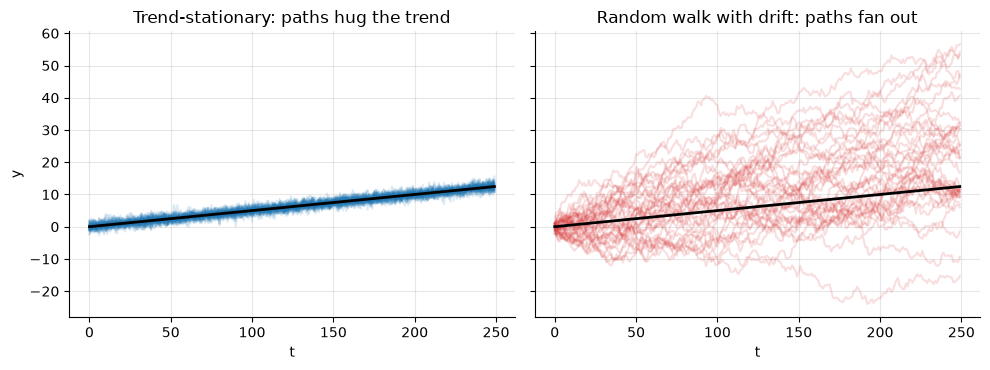

                       cross-path std @ t=50  cross-path std @ t=249
trend-stationary                        0.86                    1.14
difference-stationary                   7.66                   16.54

TS uncertainty is flat; DS uncertainty grows ~sqrt(t). Detrend the first, difference the second.


In [9]:
n_paths, n_steps = 40, 250
eps = rng.standard_normal((n_paths, n_steps))
ts_paths = 0.05 * np.arange(n_steps) + eps
ds_paths = np.cumsum(0.05 + rng.standard_normal((n_paths, n_steps)), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
axes[0].plot(ts_paths.T, color="tab:blue", alpha=0.15)
axes[0].plot(0.05 * np.arange(n_steps), color="k", lw=2)
axes[0].set(title="Trend-stationary: paths hug the trend", xlabel="t", ylabel="y")
axes[1].plot(ds_paths.T, color="tab:red", alpha=0.15)
axes[1].plot(0.05 * np.arange(n_steps), color="k", lw=2)
axes[1].set(title="Random walk with drift: paths fan out", xlabel="t")
plt.show()

spread = pd.DataFrame({
    "cross-path std @ t=50": [ts_paths[:, 50].std(), ds_paths[:, 50].std()],
    "cross-path std @ t=249": [ts_paths[:, -1].std(), ds_paths[:, -1].std()],
}, index=["trend-stationary", "difference-stationary"])
print(spread.round(2))
print("\nTS uncertainty is flat; DS uncertainty grows ~sqrt(t). "
      "Detrend the first, difference the second.")

### 2.3 The transformation toolkit, applied end-to-end

The standard moves, in the order you usually apply them:

1. **Log** (or Box–Cox): stabilizes multiplicative variance; turns growth *rates* into
   differences.
2. **Seasonal differencing** $\;y_t - y_{t-m}$: removes stable seasonality *and* much of
   the trend ("same month last year" comparisons).
3. **First differencing** $\;y_t - y_{t-1}$: removes a unit root / remaining drift.

Watch the tests flip as we push `flights` through the pipeline — this is the reasoning
behind the classic "airline model" SARIMA(0,1,1)(0,1,1)$_{12}$: one seasonal and one
regular difference of the logged series.

                               regression   ADF p KPSS p  \
raw                                     c  0.9919   0.01   
log                                     c  0.4224   0.01   
log, seasonal diff (lag 12)             c  0.0724    0.1   
log, seasonal diff, first diff          c  0.0002    0.1   

                                                 verdict  
raw                              unit root -> difference  
log                              unit root -> difference  
log, seasonal diff (lag 12)     inconclusive (low power)  
log, seasonal diff, first diff                stationary  


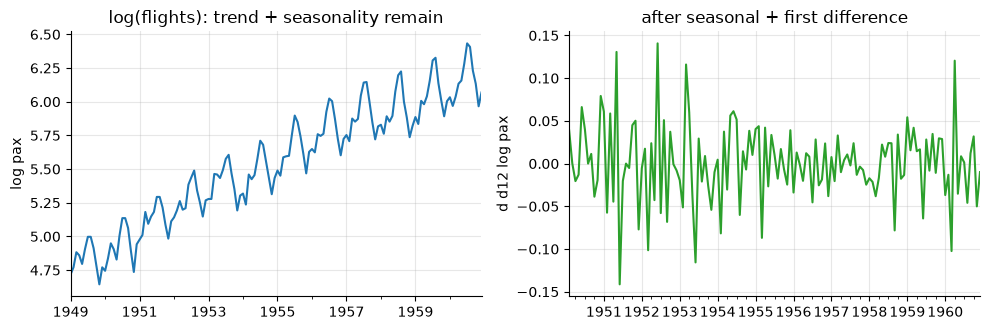

In [10]:
stages = {
    "raw": flights,
    "log": np.log(flights),
    "log, seasonal diff (lag 12)": np.log(flights).diff(12).dropna(),
    "log, seasonal diff, first diff": np.log(flights).diff(12).diff().dropna(),
}
pipeline = pd.DataFrame({name: stationarity_report(s, "c") for name, s in stages.items()}).T
print(pipeline)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
stages["log"].plot(ax=axes[0])
axes[0].set(title="log(flights): trend + seasonality remain", xlabel="", ylabel="log pax")
stages["log, seasonal diff, first diff"].plot(ax=axes[1], color="tab:green")
axes[1].set(title="after seasonal + first difference", xlabel="", ylabel="d d12 log pax")
plt.show()

Don't difference more than the tests demand — over-differencing has real costs
(variance inflation, non-invertible MA structure); we demonstrate it in the Pitfalls
section.

## 3. ACF/PACF literacy: learn the signatures by experiment

The identification logic, which we now *verify* rather than assert:

- **ACF at lag k**: correlation of $y_t$ with $y_{t-k}$, including all indirect paths.
- **PACF at lag k**: correlation of $y_t$ with $y_{t-k}$ *after* regressing out lags
  $1..k{-}1$ — the direct effect only.

So an AR(p) process (finite direct dependence) has a PACF that **cuts off** at p while
its ACF decays geometrically; an MA(q) process (finite correlation window) has an ACF
that **cuts off** at q while its PACF decays. Seasonal structure repeats the pattern at
multiples of the period.

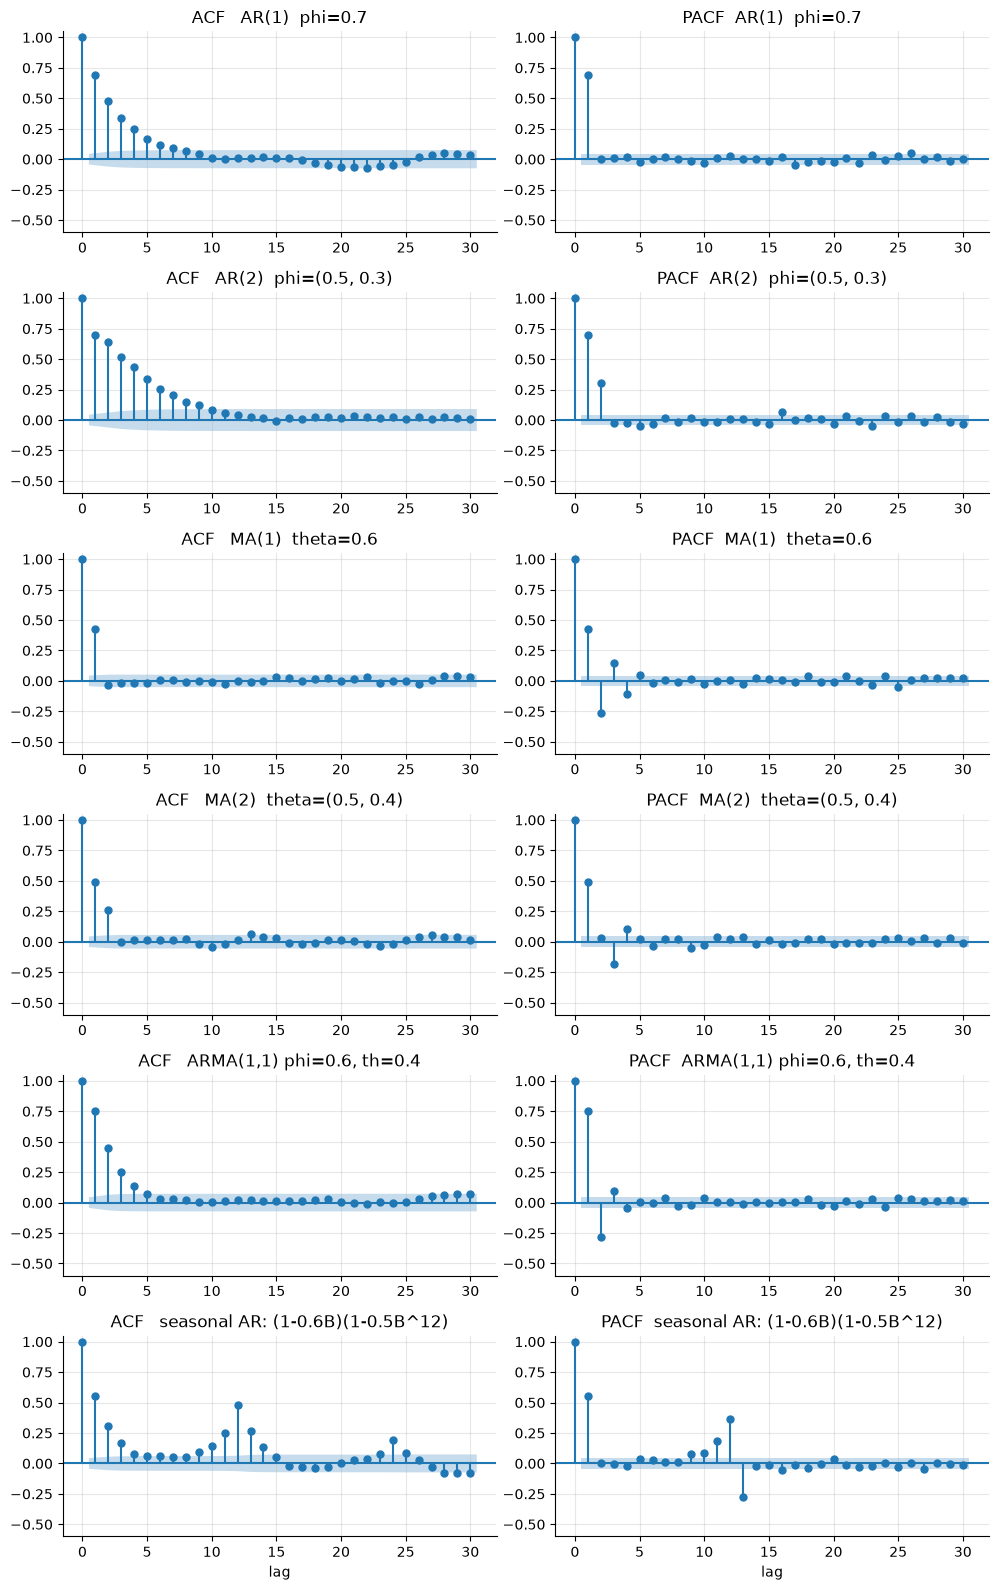

In [11]:
processes = {
    "AR(1)  phi=0.7":            ([1, -0.7], [1]),
    "AR(2)  phi=(0.5, 0.3)":     ([1, -0.5, -0.3], [1]),
    "MA(1)  theta=0.6":          ([1], [1, 0.6]),
    "MA(2)  theta=(0.5, 0.4)":   ([1], [1, 0.5, 0.4]),
    "ARMA(1,1) phi=0.6, th=0.4": ([1, -0.6], [1, 0.4]),
    "seasonal AR: (1-0.6B)(1-0.5B^12)": (np.polymul([1, -0.6],
                                                    [1] + [0] * 11 + [-0.5]), [1]),
}
n_sim = 2000
samples = {name: arma_generate_sample(np.asarray(ar, float), np.asarray(ma, float),
                                      nsample=n_sim, distrvs=rng.standard_normal,
                                      burnin=300)
           for name, (ar, ma) in processes.items()}

fig, axes = plt.subplots(len(samples), 2, figsize=(10, 16))
for i, (name, x) in enumerate(samples.items()):
    plot_acf(x, lags=30, ax=axes[i, 0], title=f"ACF   {name}")
    plot_pacf(x, lags=30, ax=axes[i, 1], method="ywm", title=f"PACF  {name}")
    axes[i, 0].set_ylim(-0.6, 1.05)
    axes[i, 1].set_ylim(-0.6, 1.05)
axes[-1, 0].set_xlabel("lag")
axes[-1, 1].set_xlabel("lag")
plt.show()

Now extract the signature *numerically*: for each simulated process, find where the ACF
and PACF first drop inside the significance band ($\pm 1.96/\sqrt{n}$), and how many of
the first 12 lags are significant (a proxy for "tails off" vs "cuts off").

In [12]:
def signature(x, nlags: int = 12) -> dict:
    ci = 1.96 / np.sqrt(len(x))
    a = acf(x, nlags=nlags, fft=True)[1:]
    p = pacf(x, nlags=nlags, method="ywadjusted")[1:]

    def cutoff(v):  # last significant lag before the first insignificant one
        k = 0
        for i, val in enumerate(v, start=1):
            if abs(val) > ci:
                k = i
            else:
                break
        return k

    return {"ACF cutoff": cutoff(a), "PACF cutoff": cutoff(p),
            "# sig ACF lags <=12": int((np.abs(a) > ci).sum()),
            "# sig PACF lags <=12": int((np.abs(p) > ci).sum())}

sig_table = pd.DataFrame({name: signature(x) for name, x in samples.items()}).T
print(sig_table)

                                  ACF cutoff  PACF cutoff  \
AR(1)  phi=0.7                             8            1   
AR(2)  phi=(0.5, 0.3)                     11            2   
MA(1)  theta=0.6                           1            5   
MA(2)  theta=(0.5, 0.4)                    2            1   
ARMA(1,1) phi=0.6, th=0.4                  5            4   
seasonal AR: (1-0.6B)(1-0.5B^12)          12            1   

                                  # sig ACF lags <=12  # sig PACF lags <=12  
AR(1)  phi=0.7                                      8                     1  
AR(2)  phi=(0.5, 0.3)                              11                     3  
MA(1)  theta=0.6                                    1                     5  
MA(2)  theta=(0.5, 0.4)                             3                     4  
ARMA(1,1) phi=0.6, th=0.4                           5                     4  
seasonal AR: (1-0.6B)(1-0.5B^12)                   12                     5  


The experiment reproduces the textbook **identification table**:

| Process | ACF | PACF |
|---|---|---|
| AR(p) | tails off (geometric) | **cuts off after lag p** |
| MA(q) | **cuts off after lag q** | tails off |
| ARMA(p,q) | tails off | tails off (use AIC/BIC to pick orders) |
| Seasonal AR/MA (period m) | same signatures **at lags m, 2m, ...** | same |

Caveats a senior candidate should volunteer:

- The cutoff readout is an estimate: with small n, sampling noise blurs it (rerun the
  cell with `n_sim=150` and watch the table degrade).
- For mixed ARMA processes eyeballing fails by design — both sides tail off. Narrow the
  menu with ACF/PACF, then let information criteria decide (Exercise 2).
- The bands assume you fed the plot a **stationary** series. ACF plots of trending
  series are meaningless — see Pitfall 1.

## 4. Spurious regression: independent random walks "correlate"

Yule (1926) called these *nonsense correlations*; Granger & Newbold (1974) showed OLS on
integrated series produces huge $t$-statistics for unrelated variables. The mechanism:
a random walk wanders, so any two finite stretches each have some drifty shape, and two
shapes almost always co-vary in-sample. More data does **not** fix it (Exercise 3) —
the sample correlation of two independent random walks does not converge to 0.

Let's quantify it: 2,000 pairs of independent random walks (n = 200 each) vs 2,000 pairs
of independent white-noise series.

Independent series, so TRUE correlation = 0 in all cases.

random-walk LEVELS:  P(|corr| > 0.5) = 37.6%   P(naive |t| > 1.96) = 83.4%
differenced:         P(|corr| > 0.5) = 0.0%   P(|t| > 1.96) = 5.3%
iid benchmark:       P(|corr| > 0.5) = 0.0%


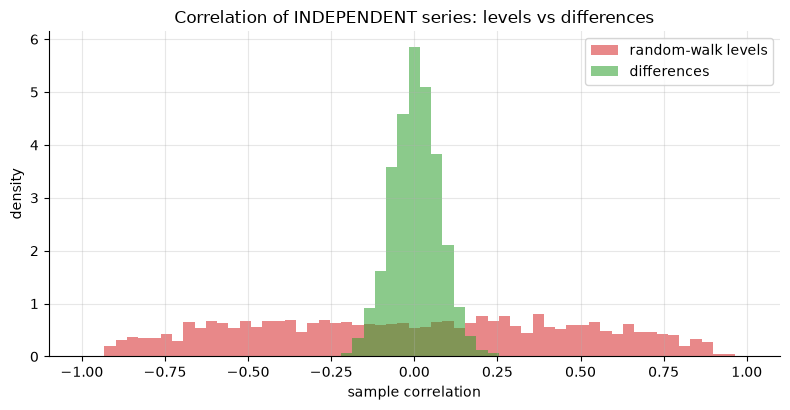

In [13]:
def row_corr(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    a = a - a.mean(axis=1, keepdims=True)
    b = b - b.mean(axis=1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))

n_pairs, n_len = 2000, 200
shocks_x = rng.standard_normal((n_pairs, n_len))
shocks_y = rng.standard_normal((n_pairs, n_len))
rw_x, rw_y = np.cumsum(shocks_x, axis=1), np.cumsum(shocks_y, axis=1)

corr_levels = row_corr(rw_x, rw_y)          # correlate the random walks (WRONG)
corr_diffs = row_corr(shocks_x, shocks_y)   # correlate the differences  (right)
corr_iid = row_corr(rng.standard_normal((n_pairs, n_len)),
                    rng.standard_normal((n_pairs, n_len)))

t_naive = corr_levels * np.sqrt((n_len - 2) / (1 - corr_levels ** 2))

print("Independent series, so TRUE correlation = 0 in all cases.\n")
print(f"random-walk LEVELS:  P(|corr| > 0.5) = {np.mean(np.abs(corr_levels) > 0.5):.1%}   "
      f"P(naive |t| > 1.96) = {np.mean(np.abs(t_naive) > 1.96):.1%}")
print(f"differenced:         P(|corr| > 0.5) = {np.mean(np.abs(corr_diffs) > 0.5):.1%}   "
      f"P(|t| > 1.96) = "
      f"{np.mean(np.abs(corr_diffs * np.sqrt((n_len-2)/(1-corr_diffs**2))) > 1.96):.1%}")
print(f"iid benchmark:       P(|corr| > 0.5) = {np.mean(np.abs(corr_iid) > 0.5):.1%}")

fig, ax = plt.subplots()
bins = np.linspace(-1, 1, 60)
ax.hist(corr_levels, bins=bins, alpha=0.55, density=True,
        label="random-walk levels", color="tab:red")
ax.hist(corr_diffs, bins=bins, alpha=0.55, density=True,
        label="differences", color="tab:green")
ax.set(title="Correlation of INDEPENDENT series: levels vs differences",
       xlabel="sample correlation", ylabel="density")
ax.legend()
plt.show()

The levels correlation is **spread across [-1, 1]** (it does not concentrate at 0),
and the naive t-test "confirms a relationship" for the large majority of independent
pairs. Differencing
collapses everything back to an honest null distribution.

### 4.1 The KPI-correlation trap

This is not an econometrics curiosity — it is the default failure mode of dashboards:

- "Feature adoption correlates 0.9 with revenue" — both grew all year. So did headcount,
  CO2, and the number of app screens. Growth correlates with growth.
- Correlation of **levels** answers "did both trend upward during this window?".
  Correlation of **changes** (or growth rates) answers "do they move together?" —
  which is the question people actually mean.

**Remedies**, in order of preference:
1. Difference / use growth rates (or week-over-week changes) before correlating.
2. Model the common drivers explicitly (trend, seasonality, marketing calendar) and
   correlate residuals.
3. If you genuinely care about a *levels* relationship (inventory vs sales, two prices),
   test for **cointegration**: the levels relationship is meaningful only if some linear
   combination of the series is stationary.

In [14]:
# Cointegration in one picture: y is driven BY x (cointegrated) vs an independent walk.
x_lvl = np.cumsum(rng.standard_normal(400))
y_coint = 2.0 + 1.5 * x_lvl + rng.normal(0, 1.0, 400)   # shares x's stochastic trend
y_indep = np.cumsum(rng.standard_normal(400))

for name, y in [("cointegrated pair", y_coint), ("independent walks", y_indep)]:
    b1, b0 = np.polyfit(x_lvl, y, 1)
    resid_lvl = y - (b0 + b1 * x_lvl)
    adf_p = adfuller(resid_lvl, regression="c", autolag="AIC")[1]
    print(f"{name:18s}: corr(levels) = {np.corrcoef(x_lvl, y)[0,1]:+.2f}, "
          f"ADF p on regression residuals = {adf_p:.4f} "
          f"-> residuals {'stationary: levels relationship is real' if adf_p < 0.05 else 'still a random walk: spurious'}")

print("\n(Engle-Granger note: proper critical values for residual-based tests are more "
      "conservative\nthan plain ADF tables; statsmodels.tsa.stattools.coint does this "
      "correctly.)")

cointegrated pair : corr(levels) = +1.00, ADF p on regression residuals = 0.0000 -> residuals stationary: levels relationship is real
independent walks : corr(levels) = -0.13, ADF p on regression residuals = 0.1295 -> residuals still a random walk: spurious

(Engle-Granger note: proper critical values for residual-based tests are more conservative
than plain ADF tables; statsmodels.tsa.stattools.coint does this correctly.)


Both pairs can show high level-correlation, but only the cointegrated pair has
*stationary* regression residuals — deviations from the fitted relationship are
self-correcting, which is what makes a levels relationship exploitable (pairs trading,
demand transfer between substitutes, inventory vs sales).

## 5. Autocorrelation breaks naive inference

Every analyst computes `mean ± 1.96 * s/sqrt(n)` on a KPI window. For an AR(1) series
with coefficient $\phi$, the true variance of the sample mean is (for large n)

$$\mathrm{Var}(\bar y) \approx \frac{\sigma_y^2}{n}\cdot\frac{1+\phi}{1-\phi},$$

i.e. the iid formula is off by a factor $(1+\phi)/(1-\phi)$: **4x** at $\phi=0.6$,
**19x** at $\phi=0.9$. Equivalently, the **effective sample size** is
$n_{\mathrm{eff}} \approx n\,(1-\phi)/(1+\phi)$ — a quarter of a year of daily data at
$\phi=0.9$ carries the information of ~10 independent observations.

We simulate coverage of nominal 95% CIs for the mean (true mean = 0), comparing:
- **naive** iid CI,
- **Newey–West / HAC** (Bartlett kernel, rule-of-thumb bandwidth),
- **AR(1) plug-in**: estimate $\hat\phi$, inflate the naive SE by
  $\sqrt{(1+\hat\phi)/(1-\hat\phi)}$,
- **oracle**: exact finite-sample SE using the true $\phi$.

In [15]:
def ar1_paths(phi: float, n: int, reps: int, rng, burn: int = 100) -> np.ndarray:
    eps = rng.standard_normal((reps, n + burn))
    return lfilter([1.0], [1.0, -phi], eps, axis=1)[:, burn:]

def nw_var_of_mean(X: np.ndarray, max_lag: int) -> np.ndarray:
    """Newey-West (Bartlett) variance of the sample mean, vectorized over rows."""
    n = X.shape[1]
    Xc = X - X.mean(axis=1, keepdims=True)
    v = (Xc ** 2).mean(axis=1)
    for lag in range(1, max_lag + 1):
        gamma = (Xc[:, lag:] * Xc[:, :-lag]).sum(axis=1) / n
        v += 2 * (1 - lag / (max_lag + 1)) * gamma
    return v / n

def exact_var_of_mean_ar1(phi: float, n: int) -> float:
    var_y = 1.0 / (1 - phi ** 2)
    k = np.arange(1, n)
    return var_y / n * (1 + 2 * np.sum((1 - k / n) * phi ** k))

n_obs, reps = 200, 3000
bandwidth = int(np.floor(4 * (n_obs / 100) ** (2 / 9)))  # Newey-West rule of thumb

rows = []
for phi in [0.0, 0.3, 0.6, 0.9]:
    X = ar1_paths(phi, n_obs, reps, rng)
    m = X.mean(axis=1)
    naive_se = X.std(axis=1, ddof=1) / np.sqrt(n_obs)
    nw_se = np.sqrt(nw_var_of_mean(X, bandwidth))
    Xc = X - m[:, None]
    phi_hat = (Xc[:, 1:] * Xc[:, :-1]).sum(1) / (Xc ** 2).sum(1)
    plug_se = naive_se * np.sqrt((1 + phi_hat) / (1 - phi_hat))
    oracle_se = np.sqrt(exact_var_of_mean_ar1(phi, n_obs))

    def cov(se):
        return np.mean(np.abs(m) <= 1.96 * se)

    rows.append({"phi": phi,
                 "SE inflation (true)": oracle_se / np.sqrt(exact_var_of_mean_ar1(0, n_obs)),
                 "n_eff": (1.0 / (1 - phi ** 2)) / exact_var_of_mean_ar1(phi, n_obs),
                 "naive cover": cov(naive_se),
                 f"NW(L={bandwidth}) cover": cov(nw_se),
                 "AR1 plug-in cover": cov(plug_se),
                 "oracle cover": cov(oracle_se)})

coverage = pd.DataFrame(rows).set_index("phi")
print(f"Nominal coverage 95%, n = {n_obs}, {reps} replications:\n")
print(coverage.round(3))

Nominal coverage 95%, n = 200, 3000 replications:

     SE inflation (true)    n_eff  naive cover  NW(L=4) cover  \
phi                                                             
0.0                1.000  200.000        0.951          0.943   
0.3                1.426  108.049        0.843          0.919   
0.6                2.488   50.473        0.661          0.874   
0.9                9.760   11.050        0.325          0.603   

     AR1 plug-in cover  oracle cover  
phi                                   
0.0              0.951         0.953  
0.3              0.943         0.949  
0.6              0.938         0.951  
0.9              0.883         0.946  


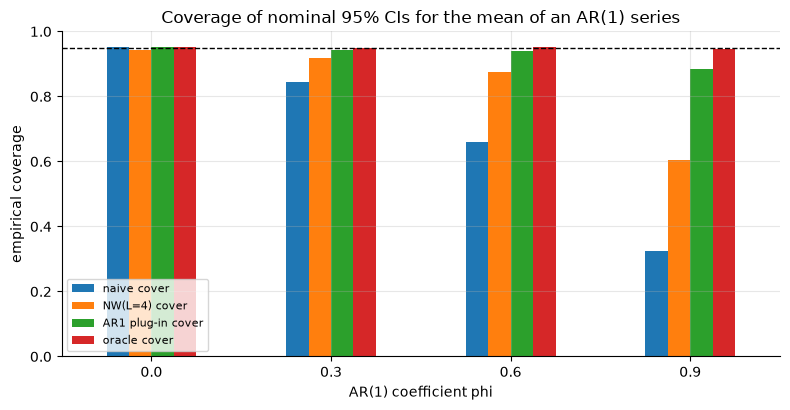

In [16]:
fig, ax = plt.subplots()
coverage[["naive cover", f"NW(L={bandwidth}) cover",
          "AR1 plug-in cover", "oracle cover"]].plot.bar(ax=ax, rot=0)
ax.axhline(0.95, color="k", ls="--", lw=1)
ax.set(title="Coverage of nominal 95% CIs for the mean of an AR(1) series",
       xlabel="AR(1) coefficient phi", ylabel="empirical coverage")
ax.legend(fontsize=8, loc="lower left")
plt.show()

What to take away (exact numbers vary by run, the ordering doesn't):

- **Naive coverage collapses** as persistence grows — at $\phi = 0.9$ the "95%" CI
  covers well under half the time. Every daily-KPI mean with a +/- band on a dashboard
  has this problem.
- **Newey–West helps but is not magic**: with the small rule-of-thumb bandwidth it still
  undercovers at high persistence (the kernel truncates long-range dependence).
  Bandwidth choice is a real degree of freedom, not a formality.
- The **AR(1) plug-in** does well when the model is right (it is here, by construction)
  but $\hat\phi$'s downward small-sample bias keeps it slightly below nominal.
- The **oracle** confirms the arithmetic: the failure was entirely in the SE formula.

The model-free alternative is the **block bootstrap**: resample contiguous blocks
(preserving within-block dependence) instead of single points. The plain iid bootstrap
fails here for exactly the same reason as `s/sqrt(n)` — it destroys the correlation
structure. See
[../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb)
for bootstrap fundamentals.

In [17]:
def moving_block_boot_means(x: np.ndarray, n_boot: int, block_len: int, rng) -> np.ndarray:
    n = len(x)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, n - block_len + 1, size=(n_boot, n_blocks))
    idx = (starts[:, :, None] + np.arange(block_len)).reshape(n_boot, -1)[:, :n]
    return x[idx].mean(axis=1)

phi_demo, block_len, reps_bb, n_boot = 0.6, 10, 1000, 500
X = ar1_paths(phi_demo, n_obs, reps_bb, rng)
covered_block = np.empty(reps_bb, dtype=bool)
covered_iid = np.empty(reps_bb, dtype=bool)
for i in range(reps_bb):
    bm = moving_block_boot_means(X[i], n_boot, block_len, rng)
    lo, hi = np.percentile(bm, [2.5, 97.5])
    covered_block[i] = lo <= 0 <= hi
    bm_iid = moving_block_boot_means(X[i], n_boot, 1, rng)  # block length 1 == iid boot
    lo, hi = np.percentile(bm_iid, [2.5, 97.5])
    covered_iid[i] = lo <= 0 <= hi

print(f"AR(1) phi={phi_demo}, n={n_obs}: 95% CI coverage")
print(f"  iid bootstrap (block length 1):  {covered_iid.mean():.1%}   <- same failure as s/sqrt(n)")
print(f"  moving-block bootstrap (len {block_len}): {covered_block.mean():.1%}")
print("\nBlock length trades off: long enough to span the dependence, short enough to "
      "leave many blocks.\nRule of thumb ~ n^(1/3); still slightly undercovers at high "
      "persistence.")

AR(1) phi=0.6, n=200: 95% CI coverage
  iid bootstrap (block length 1):  69.9%   <- same failure as s/sqrt(n)
  moving-block bootstrap (len 10): 90.0%

Block length trades off: long enough to span the dependence, short enough to leave many blocks.
Rule of thumb ~ n^(1/3); still slightly undercovers at high persistence.


## 6. Pitfalls (each demonstrated)

### Pitfall 1 — reading the ACF of a non-stationary series

The ACF of a random walk (or any trending series) decays *linearly and slowly* — every
lag looks "significant". This is not "long memory" or "strong AR structure"; it is the
trend leaking into the estimator. The ACF is only interpretable **after** you have a
stationary series.

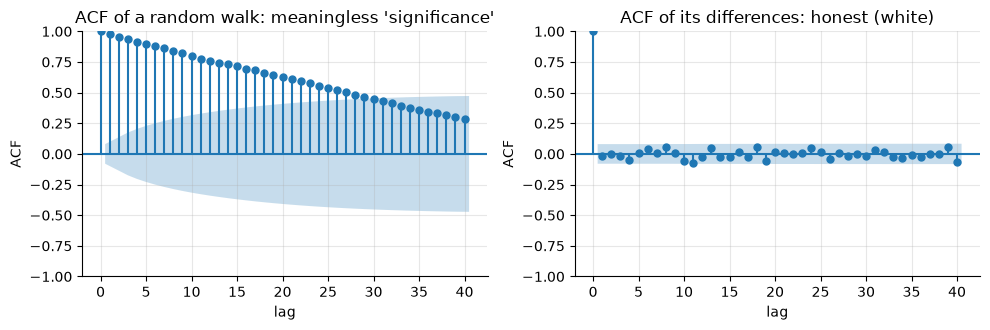

In [18]:
rw = np.cumsum(rng.standard_normal(600))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
plot_acf(rw, lags=40, ax=axes[0], title="ACF of a random walk: meaningless 'significance'")
plot_acf(np.diff(rw), lags=40, ax=axes[1], title="ACF of its differences: honest (white)")
for ax in axes:
    ax.set(xlabel="lag", ylabel="ACF")
plt.show()

### Pitfall 2 — over-differencing

Differencing is not free. Difference a series that is already stationary around a trend
and you (a) *increase* the variance and (b) manufacture an MA(1) with coefficient near
-1 (non-invertible — numerically nasty to fit, wider forecast intervals). Signature:
a strong **negative spike at lag 1** in the ACF of the differenced series.

variance after detrending (correct fix):   0.92
variance after differencing (over-diff):   1.76   ~2x sigma^2
lag-1 autocorrelation after differencing:  -0.43   (theory: -0.5)


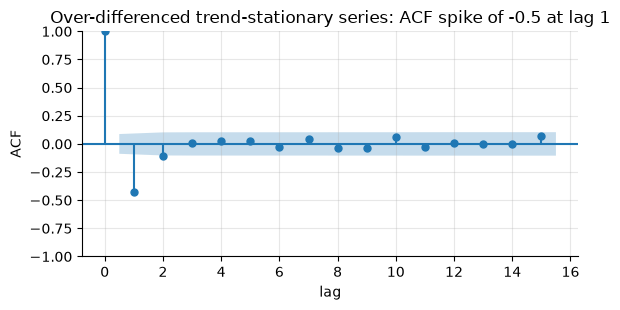

In [19]:
ts_series = 0.05 * np.arange(500) + rng.standard_normal(500)  # trend-stationary
detrended = ts_series - np.polyval(np.polyfit(np.arange(500), ts_series, 1),
                                   np.arange(500))
overdiff = np.diff(ts_series)

print(f"variance after detrending (correct fix):   {detrended.var():.2f}")
print(f"variance after differencing (over-diff):   {overdiff.var():.2f}   ~2x sigma^2")
print(f"lag-1 autocorrelation after differencing:  "
      f"{acf(overdiff, nlags=1, fft=True)[1]:+.2f}   (theory: -0.5)")

fig, ax = plt.subplots(figsize=(6, 3.2))
plot_acf(overdiff, lags=15, ax=ax,
         title="Over-differenced trend-stationary series: ACF spike of -0.5 at lag 1")
ax.set(xlabel="lag", ylabel="ACF")
plt.show()

Diagnosis before remedy: TS series -> detrend; DS series -> difference. If you see
lag-1 ACF near -0.5 after differencing, you probably differenced one time too many.

### Pitfall 3 — a structural break masquerading as a unit root

ADF's alternative hypothesis is "stationary around a *stable* mean/trend". A stationary
series with a **level shift** (product launch, pricing change, tracking migration)
violates that, and ADF often fails to reject — pushing you to difference a series that
actually needs a break dummy (Perron's critique).

ADF p, full series (with level shift): 0.549  -> 'unit root'?  No:
ADF p, first half : 0.0018   ADF p, second half: 0.0000


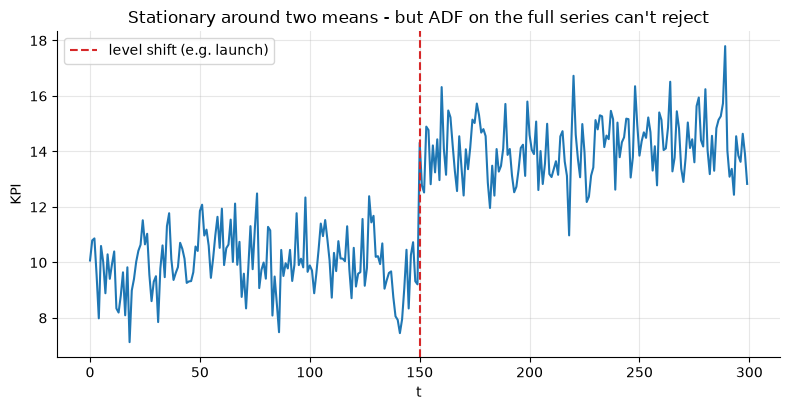

In [20]:
n_half = 150
break_series = np.concatenate([
    10 + lfilter([1.0], [1.0, -0.3], rng.standard_normal(n_half)),
    14 + lfilter([1.0], [1.0, -0.3], rng.standard_normal(n_half)),
])

p_full = adfuller(break_series, regression="c", autolag="AIC")[1]
p_first = adfuller(break_series[:n_half], regression="c", autolag="AIC")[1]
p_second = adfuller(break_series[n_half:], regression="c", autolag="AIC")[1]
print(f"ADF p, full series (with level shift): {p_full:.3f}  -> 'unit root'?  No:")
print(f"ADF p, first half : {p_first:.4f}   ADF p, second half: {p_second:.4f}")

fig, ax = plt.subplots()
ax.plot(break_series)
ax.axvline(n_half, color="tab:red", ls="--", label="level shift (e.g. launch)")
ax.set(title="Stationary around two means - but ADF on the full series can't reject",
       xlabel="t", ylabel="KPI")
ax.legend()
plt.show()

Each half is emphatically stationary; the concatenation "fails" the test. **Always plot
the series before trusting a test**, test subsamples around suspected change points, and
prefer a break dummy / segmented model over blind differencing when you know the event.

## 7. Interview corner

**Q1. "Is this series stationary — and why do you care?"**
Strong answer: define weak stationarity (constant mean/variance, lag-only
autocovariance); care because (a) sample statistics and ACF are only meaningful under
it, (b) ARMA/regression inference assumes it, (c) forecasting extrapolates a stable
distribution. Then the procedure: *plot first* (trend? seasonality? variance growth?
breaks?), run **both** ADF and KPSS, remembering they have opposite nulls; interpret via
the 2x2 grid; if a trend is visible, run the `'ct'` variants to separate trend-stationary
(detrend) from difference-stationary (difference). Volunteer the low-power caveat for
short, persistent series and the structural-break failure mode.

**Q2. "Two KPIs correlate at 0.9 — how do you react?"**
Strong answer: first question is "levels or changes?" Trending/integrated series
correlate spuriously — independent random walks give |corr| > 0.5 nearly 40% of the
time and naive t-tests endorse them ~80%+ of the time, so 0.9 in levels is weak
evidence of anything. Re-do on differences/growth rates, or
residualize on trend + seasonality + known drivers (marketing calendar). If a levels
relationship is the actual claim, test cointegration. And even a real changes-correlation
is not causal — common drivers and seasonality remain; that's an experiment/causal-
inference conversation.

**Q3. "Read this ACF plot for me."** (interviewer shows slow, near-linear decay from ~1)
Strong answer: near-1 values decaying slowly means the series is non-stationary — this
plot says "difference me", not "high-order AR". After differencing: ACF cutoff at q ->
MA(q); PACF cutoff at p -> AR(p); both tailing -> ARMA, choose by AIC/BIC; spikes at
7/12/24 etc. -> seasonal terms at that period. Mention the +/-1.96/sqrt(n) band and that
~5% of lags breach it under whiteness.

**Q4. "Additive or multiplicative seasonality — how do you decide, and what do you do?"**
Strong answer: check whether seasonal amplitude scales with level (year-wise std vs mean,
or residual-vs-level diagnostics from a quick fit of both). Multiplicative -> log (or
Box-Cox), then treat additively; that's what STL-on-log and SARIMA-on-log do. Warn about
zeros (log1p or Tweedie-style models) and about back-transform bias when averaging
forecasts on the log scale.

**Q5. "You report daily-KPI means with +/- 1.96 s/sqrt(n). What's wrong?"**
Strong answer: daily KPIs are autocorrelated; iid SEs understate the variance of the
mean by ~(1+phi)/(1-phi) for AR(1)-like dependence — 4x at phi=0.6, 19x at phi=0.9;
effective n is tiny. Fixes: HAC/Newey-West SEs (mind the bandwidth), a parametric AR
correction, or a block bootstrap; or aggregate to a coarser grain where dependence is
weak. Same issue invalidates naive t-tests on pre/post windows.

**Q6. "ADF says stationary, KPSS says non-stationary. What now?"**
Strong answer: that's the 'conflict' cell — the tests are answering different questions,
so investigate rather than average: check for a deterministic trend (rerun both with
trend terms), structural breaks (subsample tests), heteroskedasticity, or fractional
integration. Also check lag/bandwidth choices; both tests are sensitive to them. State
the decision you'd make under each resolution and, if it matters a lot downstream,
prefer the more conservative treatment for the use case (e.g. difference for forecasting;
don't difference for a cointegration analysis).

## 8. Key takeaways

- Decompose before you model: STL (robust, on logs if multiplicative) gives trend,
  seasonal, and a remainder; the remainder is where events, anomalies and model
  misspecification show up — read it, don't discard it.
- Choose additive vs multiplicative from amplitude-vs-level diagnostics; multiplicative
  -> log -> proceed additively.
- ADF and KPSS have **opposite nulls**. Use both; interpret with the 2x2 grid; run the
  trend ('ct') variants whenever the plot shows a trend.
- Trend-stationary vs difference-stationary is a *diagnosis* that dictates the *remedy*:
  detrend vs difference. Wrong remedy = over-differencing (lag-1 ACF near -0.5,
  inflated variance) or spurious dynamics.
- ACF/PACF signatures: AR(p) -> PACF cuts at p; MA(q) -> ACF cuts at q; both tail ->
  ARMA + information criteria; seasonal patterns repeat at multiples of the period.
  Only interpretable on stationary series.
- Two independent random walks correlate at |r| > 0.5 nearly 40% of the time, and
  naive t-tests endorse the relationship over 80% of the time. Correlate *changes*, not levels — or prove
  cointegration if levels are the claim.
- Autocorrelation shrinks effective sample size by (1-phi)/(1+phi); naive CIs on KPI
  means undercover badly. Fixes: Newey-West/HAC, AR plug-in corrections, block
  bootstrap.
- Tests don't replace plots: level shifts fool ADF; short persistent samples are
  genuinely ambiguous. Say so.

## 9. Exercises

**Exercise 1.** Make `flights` stationary using the *minimal* pipeline. Verify each
stage with `stationarity_report`, and state which SARIMA differencing orders (d, D) your
pipeline implies.

**Exercise 2.** Simulate an ARMA(1,1) with phi=0.5, theta=0.4 (n=800). Explain why
ACF/PACF eyeballing cannot pin down the orders, then select (p, q) with an AIC grid over
p, q in {0, 1, 2}.

**Exercise 3.** Does spurious correlation go away with more data? For independent
random-walk pairs of length n in {50, 200, 800}, estimate P(|corr| > 0.5); compare with
independent *stationary* AR(1) (phi=0.5) pairs. Explain the difference.

In [21]:
# --- Solution 1 ---
# From section 2.3: raw is trending + seasonal; log fixes the multiplicative variance
# (needed for stable inference but not itself a differencing step).
sol1 = pd.DataFrame({
    "log":                 stationarity_report(np.log(flights), "c"),
    "log + D12":           stationarity_report(np.log(flights).diff(12).dropna(), "c"),
    "log + D12 + d1":      stationarity_report(np.log(flights).diff(12).diff().dropna(), "c"),
}).T
print(sol1)
print("\nMinimal pipeline: log -> one seasonal difference (D=1, m=12) -> one regular "
      "difference (d=1).\nThat is exactly the differencing of the classic airline model "
      "SARIMA(0,1,1)(0,1,1)_12 on logs.\n(If the tests already pass after D12 for your "
      "draw of the data, d=1 is defensible either way\nhere: the seasonally differenced "
      "series retains drift-like level changes; check the ACF.)")

               regression   ADF p KPSS p                   verdict
log                     c  0.4224   0.01   unit root -> difference
log + D12               c  0.0724    0.1  inconclusive (low power)
log + D12 + d1          c  0.0002    0.1                stationary

Minimal pipeline: log -> one seasonal difference (D=1, m=12) -> one regular difference (d=1).
That is exactly the differencing of the classic airline model SARIMA(0,1,1)(0,1,1)_12 on logs.
(If the tests already pass after D12 for your draw of the data, d=1 is defensible either way
here: the seasonally differenced series retains drift-like level changes; check the ACF.)


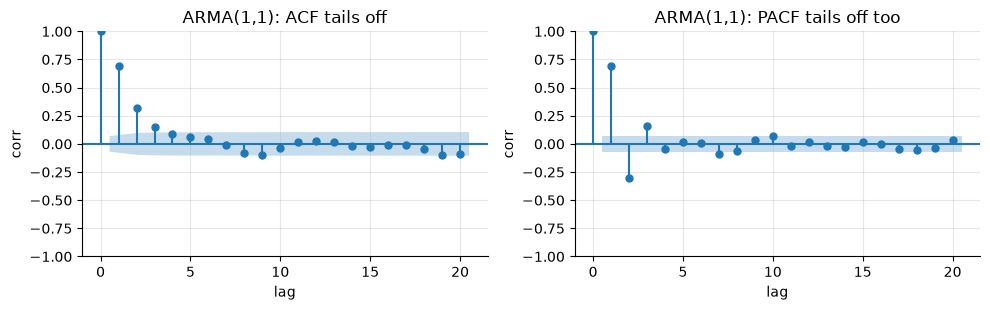

AIC grid (rows p, cols q):
q       0       1       2
p                        
0  2988.8  2485.6  2381.2
1  2467.5  2370.3  2371.2
2  2389.8  2371.6  2371.4

AIC-selected order: (p, q) = (1, 1)   [truth: (1, 1)]
Both ACF and PACF tail off geometrically - the mixed process has no clean cutoff on either side,
so eyeballing only narrows the menu; information criteria (or auto-arima) make the final call.


In [22]:
# --- Solution 2 ---
from statsmodels.tsa.arima.model import ARIMA

y_arma = arma_generate_sample(np.array([1.0, -0.5]), np.array([1.0, 0.4]),
                              nsample=800, distrvs=rng.standard_normal, burnin=200)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
plot_acf(y_arma, lags=20, ax=axes[0], title="ARMA(1,1): ACF tails off")
plot_pacf(y_arma, lags=20, ax=axes[1], method="ywm", title="ARMA(1,1): PACF tails off too")
for ax in axes:
    ax.set(xlabel="lag", ylabel="corr")
plt.show()

aic = pd.DataFrame(index=pd.Index(range(3), name="p"),
                   columns=pd.Index(range(3), name="q"), dtype=float)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # convergence chatter on over-parameterized cells
    for p in range(3):
        for q in range(3):
            aic.loc[p, q] = ARIMA(y_arma, order=(p, 0, q)).fit().aic
print("AIC grid (rows p, cols q):")
print(aic.round(1))
best = aic.stack().idxmin()
print(f"\nAIC-selected order: (p, q) = {best}   [truth: (1, 1)]")
print("Both ACF and PACF tail off geometrically - the mixed process has no clean cutoff "
      "on either side,\nso eyeballing only narrows the menu; information criteria (or "
      "auto-arima) make the final call.")

In [23]:
# --- Solution 3 ---
rows = []
for n_len_ex in [50, 200, 800]:
    rw_a = np.cumsum(rng.standard_normal((1000, n_len_ex)), axis=1)
    rw_b = np.cumsum(rng.standard_normal((1000, n_len_ex)), axis=1)
    ar_a = lfilter([1.0], [1.0, -0.5], rng.standard_normal((1000, n_len_ex + 100)),
                   axis=1)[:, 100:]
    ar_b = lfilter([1.0], [1.0, -0.5], rng.standard_normal((1000, n_len_ex + 100)),
                   axis=1)[:, 100:]
    rows.append({"n": n_len_ex,
                 "random walks: P(|corr|>0.5)": np.mean(np.abs(row_corr(rw_a, rw_b)) > 0.5),
                 "stationary AR(1): P(|corr|>0.5)": np.mean(np.abs(row_corr(ar_a, ar_b)) > 0.5)})
print(pd.DataFrame(rows).set_index("n").round(3))
print("\nFor stationary series the sample correlation is consistent: it concentrates at "
      "the true 0\nas n grows (roughly like 1/sqrt(n_eff)). For integrated series it "
      "does NOT converge -\nits distribution stays spread over [-1, 1] no matter how "
      "much history you collect.\nMore data does not rescue a levels-on-levels KPI "
      "correlation; differencing does.")

     random walks: P(|corr|>0.5)  stationary AR(1): P(|corr|>0.5)
n                                                                
50                         0.418                            0.003
200                        0.410                            0.000
800                        0.385                            0.000

For stationary series the sample correlation is consistent: it concentrates at the true 0
as n grows (roughly like 1/sqrt(n_eff)). For integrated series it does NOT converge -
its distribution stays spread over [-1, 1] no matter how much history you collect.
More data does not rescue a levels-on-levels KPI correlation; differencing does.
